In [5]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

from dotenv import load_dotenv
load_dotenv()

True

In [34]:
import glob
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_google_genai import GoogleGenerativeAIEmbeddings

DOCS_DIR  = "sample_docs"
INDEX_DIR = "faiss_index"

def load_and_split(docs_dir):
    chunks = []
    for path in glob.glob(os.path.join(docs_dir, "*.txt")):
        with open(path, "r", encoding="utf-8") as f:
            text = f.read()
        source = os.path.basename(path)
        paragraphs = [p.strip() for p in text.split("\n\n") if p.strip()]
        current = ""
        for para in paragraphs:
            if len(current) + len(para) + 2 <= 500:
                current = (current + "\n\n" + para).strip()
            else:
                if current:
                    chunks.append(Document(page_content=current, metadata={"source": source}))
                current = para
        if current:
            chunks.append(Document(page_content=current, metadata={"source": source}))
    return chunks

chunks = load_and_split(DOCS_DIR)
print(f"{len(chunks)} chunks")

11 chunks


In [35]:
embeddings  = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")
vectorstore = FAISS.from_documents(chunks, embeddings)
vectorstore.save_local(INDEX_DIR)
print(f"Index saved to {INDEX_DIR}/")

Index saved to faiss_index/


In [37]:
from langchain_core.tools import tool

@tool
def add(a: int, b: int) -> int:
    """Adds a and b."""
    return a + b

@tool
def multiply(a: int, b: int) -> int:
    """Multiplies a and b."""
    return a * b

@tool
def divide(a: int, b: int) -> float:
    """Divides a by b."""
    return a / b

In [39]:
@tool
def search_docs(query: str) -> str:
    """Search the knowledge base for information about AI/ML concepts,
    LangGraph, RAG, embeddings, transformers, and related topics."""
    embeddings  = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")
    vectorstore = FAISS.load_local(INDEX_DIR, embeddings, allow_dangerous_deserialization=True)
    docs = vectorstore.as_retriever(search_kwargs={"k": 3}).invoke(query)
    return "\n\n---\n\n".join(doc.page_content for doc in docs)

In [40]:
tools = [add, multiply, divide, search_docs]
tools_by_name = {t.name: t for t in tools}

In [41]:
from langchain_groq import ChatGroq

model = ChatGroq(model="openai/gpt-oss-20b", temperature=0)
model_with_tools = model.bind_tools(tools)

In [43]:
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage

class MessagesState(TypedDict):
    messages:  Annotated[list[AnyMessage], operator.add]
    llm_calls: int


In [44]:
from langchain_core.messages import SystemMessage, ToolMessage

def llm_call(state: MessagesState) -> dict:
    response = model_with_tools.invoke(
        [SystemMessage(content=(
            "You are a helpful assistant that can perform arithmetic "
            "and answer questions about AI/ML concepts. "
            "Use search_docs for AI/ML questions, math tools for calculations."
        ))] + state["messages"]
    )
    return {
        "messages":  [response],
        "llm_calls": state.get("llm_calls", 0) + 1,
    }


def tool_node(state: MessagesState) -> dict:
    results = []
    for tool_call in state["messages"][-1].tool_calls:
        t= tools_by_name[tool_call["name"]]
        observation = t.invoke(tool_call["args"])
        results.append(ToolMessage(content=str(observation), tool_call_id=tool_call["id"]))
    return {"messages": results}

In [45]:
from typing import Literal
from langgraph.graph import END

def should_continue(state: MessagesState) -> Literal["tool_node", "__end__"]:
    last = state["messages"][-1]
    if hasattr(last, "tool_calls") and last.tool_calls:
        return "tool_node"
    return END

In [46]:
from langgraph.graph import StateGraph, START, END


agent_builder = StateGraph(MessagesState)

agent_builder.add_node("llm_call",  llm_call)
agent_builder.add_node("tool_node", tool_node)


agent_builder.add_edge(START, "llm_call")
agent_builder.add_conditional_edges("llm_call", should_continue, ["tool_node", END])
agent_builder.add_edge("tool_node", "llm_call")

agent = agent_builder.compile()

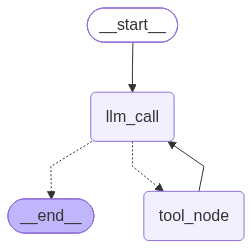

In [47]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

In [48]:
from langchain_core.messages import HumanMessage, AIMessage

def run_agent(question: str):
    print(f"Q: {question}")
    result = agent.invoke({"messages": [HumanMessage(content=question)], "llm_calls": 0})
    for msg in result["messages"]:
        if isinstance(msg, AIMessage) and msg.tool_calls:
            for tc in msg.tool_calls:
                print(f"  tool: {tc['name']}  args: {tc['args']}")
        if isinstance(msg, ToolMessage):
            print(f"  result: {msg.content[:120]}")
    print(f"A: {result['messages'][-1].content}")

In [50]:
run_agent("Who is Iqra Nishath?")

Q: Who is Iqra Nishath?
  tool: search_docs  args: {'query': 'Iqra Nishath'}
  result: Syed Lukman resume: Syed Lukman Software Engineer
sdlukhman@gmail.com +4915560195502 Munich, Germany LinkedIn Github
PRO
A: **Iqra Nishath** is a data analyst based in Berlin, Germany.  
- **Professional background**: Over three years of experience turning complex data into dashboards, automated reports, and actionable insights. She has worked at Kyndryl (formerly IBM) in Bangalore, India, and more recently as an Operations Associate at Wolt Market GmbH in Berlin.  
- **Key skills**: SQL, Python (Pandas, NumPy, scikit‑learn), Power BI, Tableau, SAP ERP, PostgreSQL, Snowflake, Kafka & Elasticsearch, Excel/Google Sheets, Docker, CI/CD, FastAPI.  
- **Notable achievements**: Improved data quality and reduced reporting failures by ~30 % at Kyndryl; automated recurring reporting workflows; built ML pipelines (e.g., a diabetes‑prediction model) and dashboards that support business decisions.  
- **Educatio

In [30]:
run_agent("Who is Syed Lukman?")

Q: Who is Syed Lukman?
  tool: search_docs  args: {'query': 'Syed Lukman'}
  result: Syed Lukman resume: Syed Lukman Software Engineer
sdlukhman@gmail.com +4915560195502 Munich, Germany LinkedIn Github
PRO
A: **Syed Lukman** is a software engineer based in Munich, Germany.  
- **Background**: Holds a Master’s in Computer Science Engineering (IU International University of Applied Sciences) and a B.E. in Electronics & Communication Engineering (MIT, Mysore).  
- **Experience**:  
  - Full‑stack engineering intern at Aampere GmbH (Oct 2026 – present).  
  - Backend engineer at Huemn.com (Sep 2022 – Aug 2023).  
  - Front‑end developer at Exuber Solutions Pvt. Ltd. (Jul 2021 – Aug 2022).  
- **Skills**: Full‑stack development (Node.js, NestJS, Next.js, React, TypeScript, Angular), databases (PostgreSQL, MongoDB, Redis), cloud & DevOps (AWS, Docker, CI/CD), and AI tooling (Cursor, Claude, Copilot).  
- **Projects**: Includes an MLOps diabetes‑prediction model, a full‑stack language testing

In [26]:
run_agent("What is LangGraph?")

Q: What is LangGraph?
  tool: search_docs  args: {'query': 'LangGraph'}
  result: LangGraph is a library built on top of LangChain for building stateful, multi-actor applications with LLMs. It models ag
A: **LangGraph** is a library built on top of LangChain that lets you design and run *stateful, multi‑actor* applications powered by large language models (LLMs).  

Key points:

| Feature | What it means |
|---------|---------------|
| **Graph‑based workflow** | You model an agent’s logic as a directed graph: nodes are functions (e.g., an LLM call, a tool invocation, or any custom code) and edges dictate the flow of control. |
| **Stateful execution** | Each node can read and update a shared state, so the agent can remember context across turns and across different actors. |
| **Cycles & branching** | The graph can contain loops (for iterative reasoning) and conditional branches, enabling complex decision trees. |
| **Persistent state** | State can be persisted between runs, making it 

In [27]:
run_agent("What is micromanagement in a corporate company?")

Q: What is micromanagement in a corporate company?
A: Micromanagement in a corporate company refers to a management style in which a supervisor or manager excessively controls, monitors, and directs the work of employees, often to the point of interfering with their autonomy and decision‑making. Key characteristics include:

| Feature | Typical Behavior |
|---------|------------------|
| **Excessive Oversight** | Constantly checking progress, demanding frequent status updates, and reviewing every detail of tasks. |
| **Limited Delegation** | Assigning tasks but also dictating how each step should be performed, leaving little room for employees to use their own judgment. |
| **Control of Processes** | Setting rigid procedures, micro‑adjusting workflows, and insisting on specific methods even when alternatives could be more efficient. |
| **Frequent Interventions** | Interrupting work to correct small issues, often before the employee has finished a task or reached a milestone. |
| **Low